# 17 · EmoGol en vivo: emociones del chat de una transmisión (EmoGol-2B)

**Proyecto:** EmoGol — Trabajo de grado, Universidad del Cauca  
**Autor:** Santiago Fernando Ortega Segura · **Director:** Ph.D. Oscar Mauricio Caicedo Rendón

## Qué hace
Escucha el chat en vivo de una transmisión de YouTube mientras el partido se juega y clasifica los
mensajes con **EmoGol-2B**, con el mismo modelo, la misma plantilla y la misma decodificación de la
evaluación (notebook `10`) y del prototipo (notebook `16`).

- La captura corre **en segundo plano**: arranca en la sección 3 y sigue sola mientras se carga el modelo
  y se consultan los resultados.
- La sección 5 se puede ejecutar **cuantas veces se quiera**: clasifica los mensajes nuevos y actualiza la
  gráfica de la evolución de las emociones durante el partido.
- La sección 6 detiene la captura y guarda los resultados en Hugging Face (`prototipo/<caso>/`).

Necesita GPU (T4) y los secretos de Colab `HF_TOKEN` y `YOUTUBE_API_KEY`. La pestaña de Colab debe
permanecer abierta durante la captura.

**Orden de uso:** 1 → 2 (ID de la transmisión) → 3 (arranca la captura) → 4 → 5 (las veces que se quiera)
→ 6 al terminar.

**Ejecución reportada en la monografía (Sección 4.3):** chat de la transmisión de Gol Caracol de la final del
Mundial Femenino Sub-20 2026 (España vs. Corea del Norte), durante la tanda de penales, el 27 de septiembre de
2026. Las salidas que se ven en este notebook corresponden a esa ejecución.

## 1. Dependencias

In [ ]:
!pip install -q -U google-api-python-client transformers accelerate peft bitsandbytes "huggingface_hub<2.0" "pandas<3" matplotlib
!pip uninstall -y -q torchao

## 2. Configuración: ID de la transmisión
El ID es lo que va después de `v=` en el enlace de la transmisión (o después de `/live/`).
En los secretos de Colab deben estar `HF_TOKEN` y `YOUTUBE_API_KEY`.

In [ ]:
from google.colab import userdata
from huggingface_hub import login

login(token=userdata.get('HF_TOKEN'))
YOUTUBE_API_KEY = userdata.get('YOUTUBE_API_KEY')

USUARIO_HF = "santiagortegasegura"
REPO_DATOS = f"{USUARIO_HF}/emotion-futbol-data"
REPO_CHECKPOINTS = f"{USUARIO_HF}/emotion-futbol-checkpoints"

VIDEO_ID_VIVO = "mhRQIhmZmtU"     # ID de la transmisión
CASO = "en_vivo_prueba"           # nombre de la carpeta en Hugging Face, sin espacios

INTERVALO_MIN_SEG = 10    # espera mínima entre consultas al chat (ahorra cuota de la API)
DURACION_MAX_HORAS = 3    # la captura se detiene sola después de este tiempo
MIN_CARACTERES = 5        # en vivo los mensajes son cortos ("GOOOL"); en el prototipo (notebook 16) el mínimo es 10
# Antispam: un mensaje de 15 o más caracteres idéntico a otro de los últimos 10 minutos se descarta
# (cadenas copiadas y pegadas). Los cantos cortos ("vamos España") sí se conservan: son reacción real.
ANTISPAM_MIN_CARACTERES = 15
ANTISPAM_MINUTOS = 10

MODEL_ID = "google/gemma-2-2b-it"
RUTA_ADAPTADOR = "gemma2_2b/adapter_final"
MAX_LENGTH = 112
TAMANO_LOTE = 16
EMOCIONES = ['alegria', 'tristeza', 'enojo', 'miedo', 'sorpresa', 'burla', 'neutral']

## 3. Arrancar la captura del chat (queda corriendo en segundo plano)
Guarda solo el texto, la hora y el id de cada mensaje (no el nombre del autor). Descarta los mensajes
largos copiados y pegados varias veces (spam). Cada consulta gasta
cuota de la API de YouTube; con una consulta cada 10 s la cuota diaria gratuita alcanza para un partido
completo. La celda termina enseguida, pero la captura sigue: usa `estado()` para ver cómo va.

In [ ]:
import re, time, threading
import pandas as pd
from googleapiclient.discovery import build

youtube = build("youtube", "v3", developerKey=YOUTUBE_API_KEY)

r = youtube.videos().list(part="snippet,liveStreamingDetails", id=VIDEO_ID_VIVO).execute()
assert r["items"], f"No se encontró el video {VIDEO_ID_VIVO}"
info_vivo = {"video_id": VIDEO_ID_VIVO,
             "titulo": r["items"][0]["snippet"]["title"],
             "canal": r["items"][0]["snippet"]["channelTitle"]}
LIVE_CHAT_ID = r["items"][0].get("liveStreamingDetails", {}).get("activeLiveChatId")
assert LIVE_CHAT_ID, "Este video no tiene un chat en vivo activo (la transmisión no ha empezado o ya terminó)."
print(f"Conectado a: {info_vivo['titulo']} ({info_vivo['canal']})")

def es_valido(texto):
    texto = texto.strip()
    if len(texto) < MIN_CARACTERES:
        return False
    if re.fullmatch(r'[^\w\s]+', texto):   # solo emojis o símbolos
        return False
    return True

def normalizar(texto):
    return " ".join(texto.lower().split())

mensajes, vistos, ultima_vez = [], set(), {}
candado = threading.Lock()
detener = threading.Event()
registro = {"consultas": 0, "recibidos": 0, "repetidos": 0, "error": None, "inicio": pd.Timestamp.now(tz="UTC")}

def es_spam(texto, momento):
    clave = normalizar(texto)
    if len(clave) < ANTISPAM_MIN_CARACTERES:
        return False
    anterior = ultima_vez.get(clave)
    ultima_vez[clave] = momento
    return anterior is not None and (momento - anterior).total_seconds() < ANTISPAM_MINUTOS * 60

def capturar():
    token, fin = None, time.time() + DURACION_MAX_HORAS * 3600
    while not detener.is_set() and time.time() < fin:
        try:
            resp = youtube.liveChatMessages().list(liveChatId=LIVE_CHAT_ID, part="snippet",
                                                   maxResults=2000, pageToken=token).execute()
        except Exception as e:
            registro["error"] = str(e)[:300]
            break
        registro["consultas"] += 1
        token = resp.get("nextPageToken")
        nuevos = []
        for item in resp.get("items", []):
            s = item.get("snippet", {})
            texto = (s.get("displayMessage") or "").strip()
            registro["recibidos"] += 1
            if item["id"] in vistos or s.get("type") != "textMessageEvent" or not es_valido(texto):
                continue
            vistos.add(item["id"])
            if es_spam(texto, pd.Timestamp(s.get("publishedAt"))):
                registro["repetidos"] += 1
                continue
            nuevos.append({"comment_id": item["id"], "created_at": s.get("publishedAt"), "text": texto})
        with candado:
            mensajes.extend(nuevos)
        espera = max(INTERVALO_MIN_SEG, resp.get("pollingIntervalMillis", 5000) / 1000)
        detener.wait(espera)

def estado():
    minutos = (pd.Timestamp.now(tz="UTC") - registro["inicio"]).total_seconds() / 60
    activo = hilo.is_alive()
    print(f"Captura {'ACTIVA' if activo else 'DETENIDA'} | {minutos:.1f} min | consultas: {registro['consultas']} | "
          f"mensajes recibidos: {registro['recibidos']} | repetidos descartados: {registro['repetidos']} | "
          f"válidos guardados: {len(mensajes)}")
    if registro["error"]:
        print(f"Último error: {registro['error']}")

hilo = threading.Thread(target=capturar, daemon=True)
hilo.start()
time.sleep(15)
estado()

Conectado a: 🔴 EN VIVO | España vs Corea del Norte: Final Mundial Femenino sub-20 | 2026 ⚽ (Gol Caracol)
Captura ACTIVA | 0.3 min | consultas: 2 | mensajes recibidos: 87 | repetidos descartados: 4 | válidos guardados: 77


## 4. Cargar EmoGol-2B (Gemma-2 2B + adaptador LoRA, igual que en la evaluación)
La captura sigue corriendo mientras el modelo carga.

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel
from huggingface_hub import snapshot_download

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16,
    bnb_4bit_use_double_quant=True,
)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left"

modelo_base = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, quantization_config=bnb_config, device_map="auto", attn_implementation="eager")
ruta = snapshot_download(repo_id=REPO_CHECKPOINTS, repo_type="dataset", allow_patterns=[f"{RUTA_ADAPTADOR}/*"])
modelo = PeftModel.from_pretrained(modelo_base, f"{ruta}/{RUTA_ADAPTADOR}")
modelo.eval()

def prompt(texto):
    return (f"Clasifica la emoción del siguiente comentario de fútbol en una de estas categorías: "
            f"{', '.join(EMOCIONES)}.\n\nComentario: {texto}\n\nEmoción:")

TOKENS_COMENTARIO = MAX_LENGTH - len(tokenizer(prompt("")).input_ids) - 2

def recortar(texto):
    ids = tokenizer(texto, add_special_tokens=False).input_ids
    return texto if len(ids) <= TOKENS_COMENTARIO else tokenizer.decode(ids[:TOKENS_COMENTARIO])

def parsear(generado):
    limpio = generado.strip().lower().split()[0] if generado.strip() else ""
    limpio = limpio.strip(".,;:!¡¿?\"'")
    return limpio if limpio in EMOCIONES else "invalido"

def clasificar(textos):
    salida_total = []
    for i in range(0, len(textos), TAMANO_LOTE):
        lote = [prompt(recortar(t)) for t in textos[i:i + TAMANO_LOTE]]
        entradas = tokenizer(lote, return_tensors="pt", padding=True, truncation=True,
                             max_length=MAX_LENGTH).to(modelo.device)
        with torch.no_grad():
            salida = modelo.generate(**entradas, max_new_tokens=6, do_sample=False,
                                     pad_token_id=tokenizer.pad_token_id)
        for j in range(len(lote)):
            salida_total.append(parsear(tokenizer.decode(salida[j][entradas['input_ids'].shape[1]:],
                                                         skip_special_tokens=True)))
    return salida_total

clasificados = pd.DataFrame(columns=["comment_id", "created_at", "text", "emocion"])
tiempo_clasificacion = {"segundos": 0.0, "n": 0}
print("EmoGol-2B cargado")
estado()

EmoGol-2B cargado
Captura ACTIVA | 2.4 min | consultas: 15 | mensajes recibidos: 279 | repetidos descartados: 36 | válidos guardados: 224


## 5. Seguimiento del partido (se puede ejecutar varias veces)
Clasifica los mensajes que llegaron desde la última vez y dibuja:
- la evolución de las emociones **por minuto de captura** (ventanas de 2 minutos; solo se grafican
  ventanas con al menos 20 mensajes);
- la distribución acumulada;
- los últimos mensajes clasificados.

Captura ACTIVA | 3.1 min | consultas: 19 | mensajes recibidos: 332 | repetidos descartados: 41 | válidos guardados: 269
Clasificados: 224 (nuevos en esta corrida: 224)
Velocidad: 5.43 mensajes/s


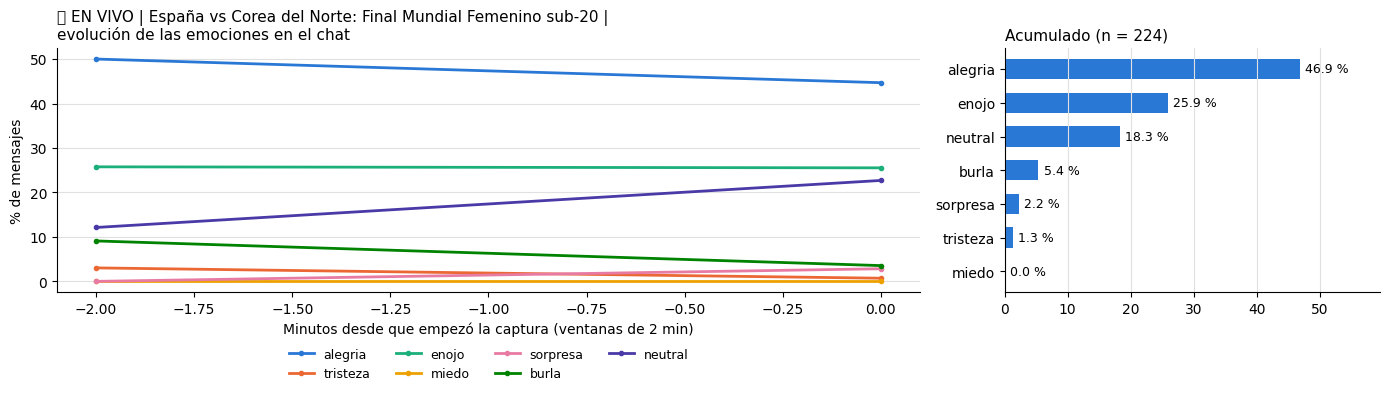


Últimos mensajes:
  [   enojo] uff esa cresca me merece
  [ alegria] gooooool
  [ alegria] goooooooool
  [ alegria] SIIIIIIIIIII VAMOSSSSS 🇪🇦🇪🇦🇪🇦🇪🇦🇪🇦🇪🇦
  [ alegria] VAMOOOOOOS
  [   enojo] PECHOFRIAS
  [   enojo] que si angel ya te entendimos deja de llamar la atencion
  [ alegria] que arquera Laia bien por ella
  [   burla] se lo devolvieron con ese tiro jajajja
  [   enojo] cómo van a ganar España otro mundial joder
  [ alegria] hay esperanzas de ganar
  [ neutral] acabo de empezar los penales?


In [ ]:
import matplotlib.pyplot as plt

VENTANA_MIN = 2
MIN_MENSAJES = 20
COLORES = {'alegria': '#2a78d6', 'tristeza': '#eb6834', 'enojo': '#1baf7a', 'miedo': '#eda100',
           'sorpresa': '#e87ba4', 'burla': '#008300', 'neutral': '#4a3aa7'}

with candado:
    pendientes = mensajes[len(clasificados):]
if pendientes:
    nuevos = pd.DataFrame(pendientes)
    t0 = time.time()
    nuevos['emocion'] = clasificar(nuevos['text'].tolist())
    tiempo_clasificacion["segundos"] += time.time() - t0
    tiempo_clasificacion["n"] += len(nuevos)
    clasificados = pd.concat([clasificados, nuevos], ignore_index=True)
estado()
print(f"Clasificados: {len(clasificados)} (nuevos en esta corrida: {len(pendientes)})")
if tiempo_clasificacion["n"]:
    print(f"Velocidad: {tiempo_clasificacion['n'] / tiempo_clasificacion['segundos']:.2f} mensajes/s")

if len(clasificados):
    d = clasificados[clasificados['emocion'] != 'invalido'].copy()
    d['created_at'] = pd.to_datetime(d['created_at'], utc=True)
    d['minuto'] = (d['created_at'] - registro["inicio"]).dt.total_seconds() / 60
    d['ventana'] = (d['minuto'] // VENTANA_MIN) * VENTANA_MIN
    conteo = d.groupby('ventana').size()
    ok = conteo[conteo >= MIN_MENSAJES].index
    tabla = (d[d['ventana'].isin(ok)].groupby('ventana')['emocion']
             .value_counts(normalize=True).unstack(fill_value=0).reindex(columns=EMOCIONES, fill_value=0) * 100)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={'width_ratios': [2.3, 1]})
    for e in EMOCIONES:
        if len(tabla):
            ax1.plot(tabla.index, tabla[e], marker='o', ms=3, lw=2, color=COLORES[e], label=e)
    ax1.set_title(f"{info_vivo['titulo'][:70]}\nevolución de las emociones en el chat", loc='left', fontsize=11)
    ax1.set_xlabel(f"Minutos desde que empezó la captura (ventanas de {VENTANA_MIN} min)")
    ax1.set_ylabel("% de mensajes")
    ax1.grid(axis='y', color='#e0e0e0'); ax1.spines[['top', 'right']].set_visible(False)
    ax1.legend(ncol=4, frameon=False, fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.18))

    dist = d['emocion'].value_counts(normalize=True).reindex(EMOCIONES, fill_value=0).sort_values() * 100
    ax2.barh(dist.index, dist.values, color='#2a78d6', height=0.6)
    for y, v in enumerate(dist.values):
        ax2.text(v + 0.8, y, f"{v:.1f} %", va='center', fontsize=9)
    ax2.set_title(f"Acumulado (n = {len(d)})", loc='left', fontsize=11)
    ax2.set_xlim(0, max(dist.values) * 1.25 + 1)
    ax2.grid(axis='x', color='#e0e0e0'); ax2.spines[['top', 'right']].set_visible(False)
    plt.tight_layout(); plt.show()

    print("\nÚltimos mensajes:")
    for _, fila in clasificados.tail(12).iterrows():
        print(f"  [{fila['emocion']:>8}] {fila['text'][:110]}")

## 6. Terminar: detener la captura, clasificar lo que falte y guardar en Hugging Face
Conviene ejecutar antes la sección 5 una última vez, para clasificar los mensajes finales y ver la gráfica completa.

In [ ]:
import json
from huggingface_hub import upload_file

detener.set(); hilo.join(timeout=30)
estado()
with candado:
    pendientes = mensajes[len(clasificados):]
if pendientes:
    nuevos = pd.DataFrame(pendientes)
    nuevos['emocion'] = clasificar(nuevos['text'].tolist())
    clasificados = pd.concat([clasificados, nuevos], ignore_index=True)

clasificados.to_csv(f"{CASO}_chat_clasificado.csv", index=False)
validos = clasificados[clasificados['emocion'] != 'invalido']
resumen = {
    "caso": CASO, **info_vivo,
    "modelo": f"{MODEL_ID} + {RUTA_ADAPTADOR}",
    "inicio_captura": str(registro["inicio"]),
    "fin_captura": str(pd.Timestamp.now(tz="UTC")),
    "consultas_api": registro["consultas"],
    "mensajes_recibidos": registro["recibidos"],
    "repetidos_descartados": registro["repetidos"],
    "mensajes_clasificados": len(clasificados),
    "pct_invalidas": round(100 * (clasificados['emocion'] == 'invalido').mean(), 2) if len(clasificados) else None,
    "mensajes_por_segundo": round(tiempo_clasificacion['n'] / tiempo_clasificacion['segundos'], 2)
                            if tiempo_clasificacion['segundos'] else None,
    "gpu": torch.cuda.get_device_name(0),
    "distribucion_pct": (validos['emocion'].value_counts(normalize=True) * 100).round(2)
                        .reindex(EMOCIONES, fill_value=0).to_dict(),
}
with open(f"{CASO}_chat_resumen.json", "w", encoding="utf-8") as f:
    json.dump(resumen, f, indent=2, ensure_ascii=False)

for archivo in [f"{CASO}_chat_clasificado.csv", f"{CASO}_chat_resumen.json"]:
    upload_file(path_or_fileobj=archivo, path_in_repo=f"prototipo/{CASO}/{archivo}",
                repo_id=REPO_DATOS, repo_type="dataset")
    print(f"Subido: prototipo/{CASO}/{archivo}")
print(json.dumps(resumen, indent=2, ensure_ascii=False))

Captura DETENIDA | 3.1 min | consultas: 19 | mensajes recibidos: 332 | repetidos descartados: 41 | válidos guardados: 269
Subido: prototipo/en_vivo_prueba/en_vivo_prueba_chat_clasificado.csv
Subido: prototipo/en_vivo_prueba/en_vivo_prueba_chat_resumen.json
{
  "caso": "en_vivo_prueba",
  "video_id": "mhRQIhmZmtU",
  "titulo": "🔴 EN VIVO | España vs Corea del Norte: Final Mundial Femenino sub-20 | 2026 ⚽",
  "canal": "Gol Caracol",
  "modelo": "google/gemma-2-2b-it + gemma2_2b/adapter_final",
  "inicio_captura": "2026-09-27 18:34:36.707097+00:00",
  "fin_captura": "2026-09-27 18:37:49.378388+00:00",
  "consultas_api": 19,
  "mensajes_recibidos": 332,
  "repetidos_descartados": 41,
  "mensajes_clasificados": 269,
  "pct_invalidas": 0.0,
  "mensajes_por_segundo": 5.43,
  "gpu": "Tesla T4",
  "distribucion_pct": {
    "alegria": 47.58,
    "tristeza": 1.49,
    "enojo": 24.91,
    "miedo": 0.0,
    "sorpresa": 2.23,
    "burla": 5.2,
    "neutral": 18.59
  }
}
